# Analisis Data Penjualan & Keuangan — Coffee Service

**Capstone Asah 2026 · Tim A26-CS276 · Learning path Data Science** (penanggung jawab: Fayyadh Tajuzzaman & Firas Razin Fauzani)

> 📝 *Draf awal yang disiapkan bersama tim. Tim Data Science perlu menjalankan ulang, memeriksa, dan menyempurnakan narasi serta temuannya.*

**Sumber data utama:** `PERHITUNGAN PENDAPTAN CEES-1.xlsx`. Ini rekap keuangan bulanan Agustus–November 2026 yang diberikan pemilik (Pak Rahmat Farhan) saat wawancara 24 Oktober 2026. Datanya **primer**, tanpa identitas pelanggan, dan dipakai terbatas untuk capstone.

## 1. Identifikasi masalah & peran data

**Masalah UMKM** (hasil wawancara): rekap kasir dicatat manual di Google Spreadsheet dan tidak tersimpan otomatis. Akibatnya rekap sering diulang, rawan salah, dan pemilik tidak bisa memantau keuangan secara *realtime*.

**Peran data dalam solusi:**
1. **Menjadi acuan struktur aplikasi.** Kolom Excel (menu, qty, HPP, harga jual, pendapatan kotor, biaya operasional) dipakai sebagai skema data dan rumus di dashboard, sehingga angka di aplikasi sama dengan cara UMKM menghitung.
2. **Memberi wawasan bisnis** yang selama ini tidak sempat dihitung: menu paling menguntungkan, titik impas, dan menu yang perlu dievaluasi.
3. **Menjadi bahan model AI.** Data ini dipakai untuk membangkitkan data latih forecasting (lihat `ai-service/`) dan sebagai konteks asisten AI.

## 2. Pertanyaan bisnis

| # | Pertanyaan | Kenapa penting bagi pemilik |
|---|---|---|
| **P1** | Menu apa yang paling banyak menyumbang **laba kotor**, dan seberapa besar ketergantungannya? | Menentukan menu andalan yang stok bahannya tidak boleh habis |
| **P2** | Bagaimana **tren omzet, laba kotor, dan laba bersih** Agustus–November? Apakah biaya tetap selalu tertutup? | Menilai kesehatan usaha dari bulan ke bulan |
| **P3** | Berapa **cup minimal per hari** agar usaha balik modal (*break-even*) setiap bulan? | Memberi target harian yang mudah dipahami kasir & pemilik |
| **P4** | Menu mana yang **margin-nya tinggi tetapi kurang laku**, dan menu mana yang **merugikan atau tidak laku**? | Dasar keputusan promosi & evaluasi menu |

Pertanyaan tentang **jam/hari ramai** belum bisa dijawab. Excel UMKM hanya berisi rekap bulanan, dan data harian di aplikasi saat ini masih *dummy*. Pertanyaan ini dijawab setelah aplikasi dipakai dan mengumpulkan transaksi riil.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
RAW_XLSX = DATA / "raw" / "PERHITUNGAN PENDAPTAN CEES-1.xlsx"
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
OUT = DATA / "processed"; OUT.mkdir(exist_ok=True)

pd.set_option("display.float_format", lambda v: f"{v:,.0f}".replace(",", "."))
rp = lambda v: "Rp" + f"{v:,.0f}".replace(",", ".")
# Gaya grafik: tipis, grid samar, satu warna per seri (palet tervalidasi untuk buta warna)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ece9e4", "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a8a29e"
MONTH_ORDER = ["AGUSTUS", "SEPTEMBER", "OKTOBER", "NOVEMBER"]

## 3. Data wrangling
### 3.1 Gathering data

In [2]:
xl = pd.ExcelFile(RAW_XLSX)
print("Sheet:", xl.sheet_names)
raw = {sh: pd.read_excel(RAW_XLSX, sheet_name=sh, header=None) for sh in xl.sheet_names}
raw["AGUSTUS"].head(32)

Sheet: ['AGUSTUS', 'SEPTEMBER', 'OKTOBER', 'NOVEMBER']


,0,1,2,3,4,5
0,NAMA MENU,QTY,HPP,TOTAL HPP,HARGA JUAL,PENDAPATAN KOTOR
1,Ice Sanger Cees,140,7893,1105020,18000,2520000
2,Hot Sanger Cees,36,6038,217368,15000,540000
3,Ice kopi Susu Cees,29,6662,193198,21000,609000
4,SANGER CEES PROMO,27,7893,213111,10000,270000
5,Ice Long Black,45,3577,160965,15000,675000
6,Hot Long Black,17,3561,60537,13000,221000
7,Black Moon,12,7097,85164,18000,216000
8,Black Peach,32,3292,105344,18000,576000
9,Ice black Tea,12,2737,32844,12000,144000


Setiap sheet adalah satu bulan dengan struktur yang sama:
- baris menu (kolom A–F: Nama Menu, Qty, HPP, Total HPP, Harga Jual, Pendapatan Kotor),
- baris `TOTAL`,
- baris `TOTAL PENDAPATAN - HPP`,
- 4 baris biaya operasional (Gaji Barista, Token, PDAM, Sewa Toko),
- baris `TOTAL PENDAPATAN BERSIH`.

### 3.2 Assessing data (menilai kualitas data)

In [3]:
COST_NAMES = {"GAJI BARISTA", "TOKEN", "PDAM", "SEWA TOKO"}

def split_sheet(df, month):
    menu_rows, cost_rows, totals = [], [], {}
    for _, r in df.iloc[1:].iterrows():
        label = r[0]
        if pd.isna(label):
            continue
        key = str(label).strip().upper()
        if key in COST_NAMES:
            cost_rows.append({"bulan": month, "biaya": key, "nominal": r[1]})
        elif key.startswith("TOTAL"):
            totals[key] = {"qty": r[1], "total_hpp": r[3], "pendapatan_kotor": r[5]}
        else:
            menu_rows.append({"bulan": month, "menu_asli": label, "qty": r[1], "hpp": r[2],
                              "total_hpp": r[3], "harga_jual": r[4], "pendapatan_kotor": r[5]})
    return pd.DataFrame(menu_rows), pd.DataFrame(cost_rows), totals

parts = {m: split_sheet(raw[m], m) for m in MONTH_ORDER}
menu_raw = pd.concat([p[0] for p in parts.values()], ignore_index=True)
cost_raw = pd.concat([p[1] for p in parts.values()], ignore_index=True)
excel_totals = {m: p[2] for m, p in parts.items()}

issues = {
    "Nama menu dengan spasi di awal/akhir": sorted(menu_raw.loc[menu_raw.menu_asli != menu_raw.menu_asli.str.strip(), "menu_asli"].unique()),
    "Kapitalisasi tidak konsisten": sorted(menu_raw.loc[menu_raw.menu_asli.str.strip() != menu_raw.menu_asli.str.strip().str.title(), "menu_asli"].str.strip().unique()),
    "Qty kosong (NaN)": menu_raw.loc[menu_raw.qty.isna(), ["bulan", "menu_asli"]].values.tolist(),
    "Menu hanya ada di sebagian bulan": sorted(set(menu_raw.menu_asli.str.strip().str.title().value_counts().loc[lambda s: s < 4].index)),
    "Baris TOTAL qty kosong": [m for m, t in excel_totals.items() if pd.isna(t["TOTAL"]["qty"])],
    "Duplikat menu dalam satu bulan": int(menu_raw.assign(m=menu_raw.menu_asli.str.strip().str.title()).duplicated(["bulan", "m"]).sum()),
}
for k, v in issues.items():
    print(f"• {k}: {v}")

• Nama menu dengan spasi di awal/akhir: ['Aren Latte ', 'Espresso ', 'Extra Shot ', 'Hot Kopi Susu Cees ', 'Hot Long Black ', 'Hot Sanger Cees ', 'Ice Sanger Cees ', 'Ice black Tea ', 'SANGER CEES PROMO ']
• Kapitalisasi tidak konsisten: ['Ice black Tea', 'Ice kopi Susu Cees', 'SANGER CEES PROMO']
• Qty kosong (NaN): [['AGUSTUS', 'Sunny Lemon'], ['SEPTEMBER', 'Hot Black Tea'], ['SEPTEMBER', 'Sunny Lemon'], ['OKTOBER', 'Sunny Lemon'], ['NOVEMBER', 'Hot Kopi Susu Cees '], ['NOVEMBER', 'Ice black Tea '], ['NOVEMBER', 'Hot Black Tea'], ['NOVEMBER', 'Sunny Lemon']]
• Menu hanya ada di sebagian bulan: ['Hot Kopi Susu Cees', 'Sanger Cees Promo']
• Baris TOTAL qty kosong: ['NOVEMBER']
• Duplikat menu dalam satu bulan: 0


In [4]:
# Apakah HPP & harga jual tiap menu konsisten antarbulan?
tmp = menu_raw.assign(menu=menu_raw.menu_asli.str.strip().str.title())
print("Jumlah nilai unik HPP/harga per menu (1 = konsisten):", tmp.groupby("menu")[["hpp", "harga_jual"]].nunique().max().to_dict())
# Apakah rumus Excel benar? total_hpp = qty x hpp, pendapatan = qty x harga
chk = tmp.fillna({"qty": 0})
print("Baris dengan total HPP tidak sesuai rumus :", int((chk.total_hpp != chk.qty * chk.hpp).sum()))
print("Baris dengan pendapatan tidak sesuai rumus:", int((chk.pendapatan_kotor != chk.qty * chk.harga_jual).sum()))

Jumlah nilai unik HPP/harga per menu (1 = konsisten): {'hpp': 1, 'harga_jual': 1}
Baris dengan total HPP tidak sesuai rumus : 0
Baris dengan pendapatan tidak sesuai rumus: 0


**Ringkasan kualitas data:**

| Temuan | Dampak | Penanganan |
|---|---|---|
| 9 nama menu memiliki spasi di akhir (mis. `"Ice Sanger Cees "`) | Menu yang sama terhitung berbeda saat digabung | `strip()` + rapikan spasi ganda |
| Kapitalisasi tidak konsisten (`"Ice black Tea"`, `"Ice kopi Susu Cees"`, `"SANGER CEES PROMO"`) | Sama seperti di atas | Ubah ke *Title Case* |
| Qty kosong pada menu yang tidak terjual (mis. Sunny Lemon) | Dianggap *missing*, padahal artinya 0 | Isi dengan 0 (pendapatan di baris itu juga 0) |
| Hot Kopi Susu Cees tidak ada di sheet Agustus | Bukan error: menu baru mulai September | Dibiarkan; qty Agustus = 0 |
| Baris `TOTAL` qty November kosong | Total cup November tidak tercatat | Dihitung ulang dari baris menu |
| November **parsial** (bulan belum selesai) tetapi biaya tetap dicatat penuh | Laba bersih November tampak minus | Dibandingkan memakai rata-rata **per hari**, dengan asumsi data November mencakup tanggal 1–12 |

Hal yang sudah benar: rumus Excel konsisten (Total HPP = qty × HPP, Pendapatan = qty × Harga), dan HPP serta harga tiap menu sama di semua bulan.

### 3.3 Cleaning data

In [5]:
menu = menu_raw.copy()
menu["menu"] = menu.menu_asli.str.strip().str.replace(r"\s+", " ", regex=True).str.title()
menu["qty"] = menu.qty.fillna(0).astype(int)
menu["total_hpp"] = menu.qty * menu.hpp
menu["pendapatan_kotor"] = menu.qty * menu.harga_jual
menu["laba_kotor"] = menu.pendapatan_kotor - menu.total_hpp
menu["bulan"] = pd.Categorical(menu.bulan, MONTH_ORDER, ordered=True)
menu = menu[["bulan", "menu", "qty", "hpp", "harga_jual", "total_hpp", "pendapatan_kotor", "laba_kotor"]]

cost = cost_raw.assign(biaya=cost_raw.biaya.str.title(), bulan=pd.Categorical(cost_raw.bulan, MONTH_ORDER, ordered=True))

# Verifikasi: hasil cleaning harus sama dengan baris TOTAL di Excel
for m in MONTH_ORDER:
    t = excel_totals[m]
    ours = menu[menu.bulan == m]
    assert ours.pendapatan_kotor.sum() == t["TOTAL"]["pendapatan_kotor"], m
    assert ours.total_hpp.sum() == t["TOTAL"]["total_hpp"], m
    net_excel = t["TOTAL PENDAPATAN BERSIH"]["qty"]
    assert ours.laba_kotor.sum() - cost[cost.bulan == m].nominal.sum() == net_excel, m
print("✓ Semua total hasil cleaning sama persis dengan baris TOTAL di Excel UMKM.")
menu.head()

✓ Semua total hasil cleaning sama persis dengan baris TOTAL di Excel UMKM.


,bulan,menu,qty,hpp,harga_jual,total_hpp,pendapatan_kotor,laba_kotor
0,AGUSTUS,Ice Sanger Cees,140,7893,18000,1105020,2520000,1414980
1,AGUSTUS,Hot Sanger Cees,36,6038,15000,217368,540000,322632
2,AGUSTUS,Ice Kopi Susu Cees,29,6662,21000,193198,609000,415802
3,AGUSTUS,Sanger Cees Promo,27,7893,10000,213111,270000,56889
4,AGUSTUS,Ice Long Black,45,3577,15000,160965,675000,514035


## 4. Exploratory & explanatory analysis
### P1 — Menu penyumbang laba kotor terbesar

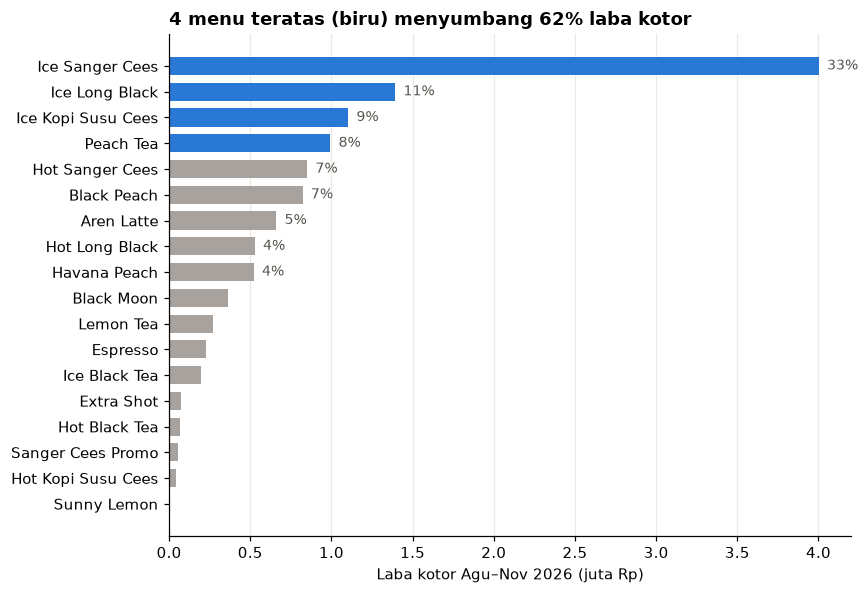

,qty,pendapatan,laba_kotor,harga,hpp,porsi_laba_%,kumulatif_%,margin_%
menu,,,,,,,,
Ice Sanger Cees,396,7128000,4002372,18000,7893,33,33,56
Ice Long Black,122,1830000,1393606,15000,3577,12,44,76
Ice Kopi Susu Cees,77,1617000,1104026,21000,6662,9,53,68
Peach Tea,83,1411000,993925,17000,5025,8,62,70
Hot Sanger Cees,95,1425000,851390,15000,6038,7,69,60
Black Peach,56,1008000,823648,18000,3292,7,75,82
Aren Latte,49,1029000,661402,21000,7502,5,81,64
Hot Long Black,56,728000,528584,13000,3561,4,85,73
Havana Peach,37,777000,522255,21000,6885,4,89,67


In [6]:
per_menu = (menu.groupby("menu").agg(qty=("qty", "sum"), pendapatan=("pendapatan_kotor", "sum"),
            laba_kotor=("laba_kotor", "sum"), harga=("harga_jual", "first"), hpp=("hpp", "first"))
            .sort_values("laba_kotor", ascending=False))
per_menu["porsi_laba_%"] = per_menu.laba_kotor / per_menu.laba_kotor.sum() * 100
per_menu["kumulatif_%"] = per_menu["porsi_laba_%"].cumsum()
per_menu["margin_%"] = (per_menu.harga - per_menu.hpp) / per_menu.harga * 100

fig, ax = plt.subplots(figsize=(8, 5.5))
d = per_menu.sort_values("laba_kotor")
ax.barh(d.index, d.laba_kotor / 1e6, color=[BLUE if i >= len(d) - 4 else GRAY for i in range(len(d))], height=0.7)
for y, (v, s) in enumerate(zip(d.laba_kotor, d["porsi_laba_%"])):
    if s >= 4: ax.text(v / 1e6 + 0.05, y, f"{s:.0f}%", va="center", fontsize=9, color="#57534e")
ax.set_xlabel("Laba kotor Agu–Nov 2026 (juta Rp)")
ax.set_title("4 menu teratas (biru) menyumbang 62% laba kotor", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "p1_laba_per_menu.png"); plt.show()
per_menu.round(1)

**Jawaban P1:**
- **Ice Sanger Cees** adalah tulang punggung usaha. Menu ini menyumbang **±33% laba kotor** (396 cup, ±Rp4,0 juta).
- **4 menu teratas** (Ice Sanger Cees, Ice Long Black, Ice Kopi Susu Cees, Peach Tea) menyumbang **±62%**. Tujuh menu teratas sudah mencapai **±81%**, sehingga polanya mirip prinsip Pareto.
- **Menu dingin (Ice) mendominasi**, sesuai iklim Banda Aceh.

### P2 — Tren omzet, laba kotor & laba bersih per bulan

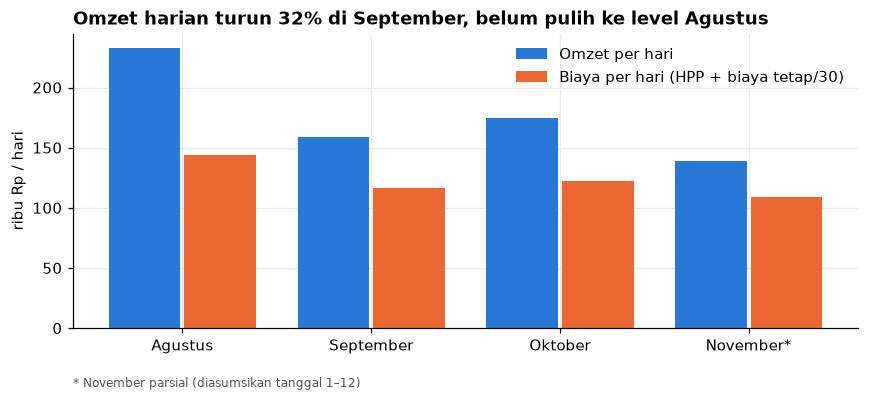

,cup,omzet,hpp,laba_kotor,biaya_tetap,laba_bersih,hari_data,omzet_per_hari,cup_per_hari,perubahan_omzet_harian_%
bulan,,,,,,,,,,
AGUSTUS,440,7227000,2647388,4579612,1763333,2816279,31,233.129,14,NaN
SEPTEMBER,278,4762000,1741811,3020189,1763333,1256856,30,158.733,9,-32
OKTOBER,329,5421000,1921988,3499012,1813333,1685679,31,174.871,11,10
NOVEMBER,99,1669000,599734,1069266,1763333,-694067,12,139.083,8,-20


In [7]:
DAYS = {"AGUSTUS": 31, "SEPTEMBER": 30, "OKTOBER": 31, "NOVEMBER": 12}  # asumsi: data November = tgl 1–12
monthly = menu.groupby("bulan", observed=True).agg(cup=("qty", "sum"), omzet=("pendapatan_kotor", "sum"),
                                                     hpp=("total_hpp", "sum"), laba_kotor=("laba_kotor", "sum"))
monthly["biaya_tetap"] = cost.groupby("bulan", observed=True).nominal.sum()
monthly["laba_bersih"] = monthly.laba_kotor - monthly.biaya_tetap
monthly["hari_data"] = [DAYS[m] for m in monthly.index]
monthly["omzet_per_hari"] = monthly.omzet / monthly.hari_data
monthly["cup_per_hari"] = monthly.cup / monthly.hari_data
monthly["perubahan_omzet_harian_%"] = monthly.omzet_per_hari.pct_change() * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(monthly)); w = 0.38
ax.bar(x - w/2 - 0.01, monthly.omzet_per_hari / 1e3, w, color=BLUE, label="Omzet per hari")
ax.bar(x + w/2 + 0.01, (monthly.hpp + monthly.biaya_tetap * monthly.hari_data / 30) / monthly.hari_data / 1e3, w,
       color=ORANGE, label="Biaya per hari (HPP + biaya tetap/30)")
ax.set_xticks(x, [m.title() + ("*" if m == "NOVEMBER" else "") for m in monthly.index])
ax.set_ylabel("ribu Rp / hari"); ax.legend(frameon=False, loc="upper right")
ax.set_title("Omzet harian turun 32% di September, belum pulih ke level Agustus", loc="left", fontweight="bold")
ax.text(0, -0.2, "* November parsial (diasumsikan tanggal 1–12)", transform=ax.transAxes, fontsize=8, color="#57534e")
plt.tight_layout(); plt.savefig(FIG / "p2_tren_bulanan.png"); plt.show()
monthly.round(1)

**Jawaban P2:**
- **Omzet per hari** turun dari ±Rp233 ribu (Agustus) ke ±Rp159 ribu (September, **−32%**), naik sedikit di Oktober (±Rp175 ribu), lalu turun lagi di awal November (±Rp139 ribu).
- **Laba bersih** Agustus ±Rp2,8 juta, September ±Rp1,3 juta, dan Oktober ±Rp1,7 juta. Jadi **biaya tetap (±Rp1,76–1,81 juta/bulan) selalu tertutup** untuk bulan yang penuh.
- Angka laba bersih November (−Rp694 ribu) **tidak bisa langsung dibandingkan**. Datanya baru beberapa hari, sedangkan biaya tetap sudah dicatat sebulan penuh.
- Penyebab turunnya penjualan setelah Agustus tidak bisa dipastikan dari data ini. Kemungkinannya efek bulan pembukaan atau promo, tetapi ini perlu dikonfirmasi ke pemilik.

### P3 — Titik impas (break-even): berapa cup per hari?

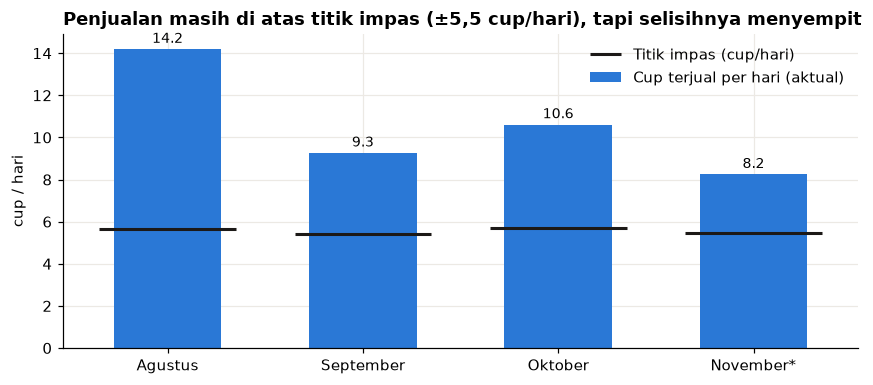

,cup_per_hari,laba_kotor_per_cup,bep_cup_per_bulan,bep_cup_per_hari,margin_aman_%
bulan,,,,,
AGUSTUS,14,10.408,169,6,151
SEPTEMBER,9,10.864,162,5,71
OKTOBER,11,10.635,170,6,87
NOVEMBER,8,10.801,163,5,52


In [8]:
monthly["laba_kotor_per_cup"] = monthly.laba_kotor / monthly.cup
monthly["bep_cup_per_bulan"] = monthly.biaya_tetap / monthly.laba_kotor_per_cup
monthly["bep_cup_per_hari"] = monthly.bep_cup_per_bulan / 30
monthly["margin_aman_%"] = (monthly.cup_per_hari / monthly.bep_cup_per_hari - 1) * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x, monthly.cup_per_hari, 0.55, color=BLUE, label="Cup terjual per hari (aktual)")
ax.hlines(monthly.bep_cup_per_hari, x - 0.35, x + 0.35, colors="#1c1917", linewidth=2, label="Titik impas (cup/hari)")
for i, (a, b) in enumerate(zip(monthly.cup_per_hari, monthly.bep_cup_per_hari)):
    ax.text(i, a + 0.3, f"{a:.1f}", ha="center", fontsize=9)
ax.set_xticks(x, [m.title() + ("*" if m == "NOVEMBER" else "") for m in monthly.index])
ax.set_ylabel("cup / hari"); ax.legend(frameon=False, loc="upper right")
ax.set_title("Penjualan masih di atas titik impas (±5,5 cup/hari), tapi selisihnya menyempit", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "p3_break_even.png"); plt.show()
monthly[["cup_per_hari", "laba_kotor_per_cup", "bep_cup_per_bulan", "bep_cup_per_hari", "margin_aman_%"]].round(1)

**Jawaban P3:**
- Setiap cup rata-rata menghasilkan laba kotor **±Rp10.400–10.900**. Dengan biaya tetap ±Rp1,76 juta/bulan, usaha **balik modal di ±162–171 cup per bulan**, atau **±5,5 cup per hari**.
- Penjualan aktual: 14,2 cup/hari (Agustus), 9,3 (September), 10,6 (Oktober), dan ±8,2 (awal November). Semuanya masih di atas titik impas, tetapi **margin aman menyusut** dari ±150% di Agustus menjadi ±50% di awal November.
- Target sederhana untuk kasir: **minimal 6 cup/hari agar tidak rugi, dan 10+ cup/hari agar sehat**. Target ini bisa ditampilkan di dashboard.

### P4 — Margin vs popularitas menu

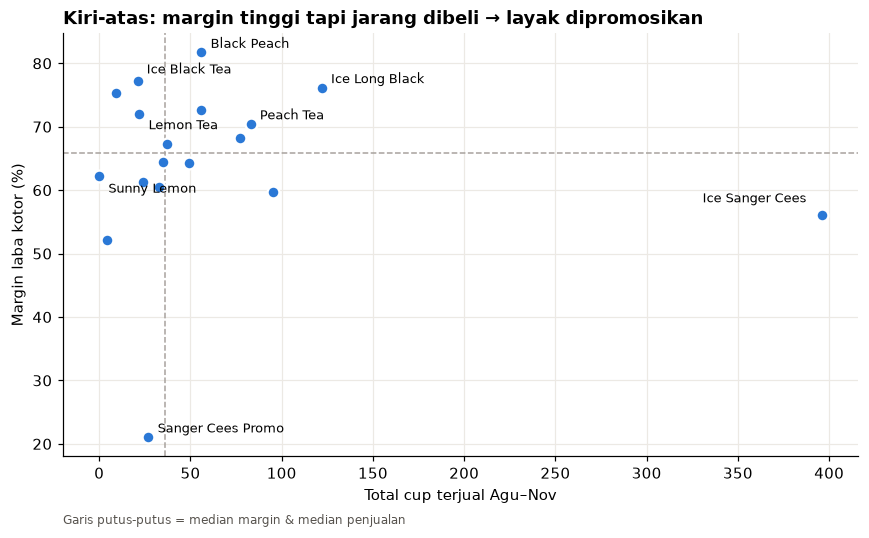

,qty,harga,hpp,margin_%
menu,,,,
Black Peach,56,18000,3292,82
Ice Black Tea,21,12000,2737,77
Ice Long Black,122,15000,3577,76
Hot Black Tea,9,10000,2471,75
Hot Long Black,56,13000,3561,73
Lemon Tea,22,17000,4757,72
Peach Tea,83,17000,5025,70
Ice Kopi Susu Cees,77,21000,6662,68
Havana Peach,37,21000,6885,67


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(per_menu.qty, per_menu["margin_%"], s=60, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
LABEL = {"Ice Sanger Cees": (-10, 8), "Ice Long Black": (6, 3), "Black Peach": (6, 3), "Ice Black Tea": (6, 5),
         "Lemon Tea": (6, -10), "Sanger Cees Promo": (6, 3), "Sunny Lemon": (6, -11), "Peach Tea": (6, 3)}
for name, r in per_menu.iterrows():
    if name in LABEL:
        ax.annotate(name, (r.qty, r["margin_%"]), xytext=LABEL[name], textcoords="offset points", fontsize=8.5,
                    ha="right" if name == "Ice Sanger Cees" else "left")
ax.axhline(per_menu["margin_%"].median(), color=GRAY, linestyle="--", linewidth=1)
ax.axvline(per_menu.qty.median(), color=GRAY, linestyle="--", linewidth=1)
ax.set_xlabel("Total cup terjual Agu–Nov"); ax.set_ylabel("Margin laba kotor (%)")
ax.set_title("Kiri-atas: margin tinggi tapi jarang dibeli → layak dipromosikan", loc="left", fontweight="bold")
ax.text(0, -0.16, "Garis putus-putus = median margin & median penjualan", transform=ax.transAxes, fontsize=8, color="#57534e")
plt.tight_layout(); plt.savefig(FIG / "p4_margin_vs_qty.png"); plt.show()
per_menu[["qty", "harga", "hpp", "margin_%"]].sort_values("margin_%", ascending=False).round(1)

**Jawaban P4:**
- **Margin tinggi tetapi kurang laku:** Black Peach (margin **±82%**, 56 cup), Ice Black Tea (±77%, 21 cup), Hot Black Tea (±75%), dan Lemon Tea (±72%, 22 cup). Setiap tambahan penjualan dari menu ini sangat menguntungkan, sehingga layak dipromosikan.
- **Sanger Cees Promo** hanya bermargin **±21%** (laba Rp2.107/cup), padahal Ice Sanger Cees normal bermargin ±56% (Rp10.107/cup). Satu cup promo menghasilkan laba **5× lebih kecil**. Menu ini hanya terjual di Agustus.
- **Sunny Lemon tidak terjual sama sekali selama 4 bulan.** Jika bahannya tetap distok, ada risiko bahan terbuang.

## 5. Kesimpulan & rekomendasi untuk Coffee Service

1. **Jaga ketersediaan bahan Ice Sanger Cees dan 3 menu teratas lainnya.** Keempatnya menghasilkan ±62% laba kotor. Fitur *Prediksi 7 hari* di dashboard membantu menyiapkan stok bahan.
2. **Pasang target harian: minimal 6 cup (impas), sasaran 10+ cup.** Pantau lewat kartu "Cup terjual" di dashboard.
3. **Dorong penjualan menu bermargin tinggi** (Black Peach, Ice Black Tea, Lemon Tea). Caranya bisa lewat konten Instagram/TikTok atau paket bundling dengan Ice Sanger Cees.
4. **Hati-hati dengan promo bermargin rendah.** Jika ingin promo, pilih menu dengan HPP rendah (misalnya teh) atau buat diskon kecil, bukan potongan harga besar seperti Sanger Cees Promo.
5. **Evaluasi Sunny Lemon:** ganti resep, promosikan, atau keluarkan dari menu agar bahan tidak terbuang.
6. **Konfirmasi ke pemilik** penyebab turunnya penjualan setelah Agustus. Setelah aplikasi mencatat transaksi harian riil, lanjutkan analisis **jam dan hari ramai** untuk mengatur jadwal barista.

## 6. Penyediaan data untuk tim lain

In [10]:
menu.to_csv(OUT / "penjualan_menu_bulanan.csv", index=False)
cost.to_csv(OUT / "biaya_operasional_bulanan.csv", index=False)
monthly.reset_index().to_csv(OUT / "ringkasan_bulanan.csv", index=False)
per_menu.reset_index().to_csv(OUT / "ringkasan_per_menu.csv", index=False)
for f in sorted(OUT.glob("*.csv")):
    print(f"✓ {f.name:<32} {len(pd.read_csv(f)):>3} baris")

✓ biaya_operasional_bulanan.csv     16 baris
✓ penjualan_menu_bulanan.csv        68 baris
✓ ringkasan_bulanan.csv              4 baris
✓ ringkasan_per_menu.csv            18 baris


Penjelasan setiap kolom ada di [`DATA_DICTIONARY.md`](../DATA_DICTIONARY.md). Cara pemakaian oleh tim lain:
- **Full-Stack:** `ringkasan_per_menu.csv` cocok dengan menu, HPP, dan harga di seed database (`backend/prisma/seedData.js`).
- **AI Engineer:** data transaksi harian untuk forecasting diproses di `ai-service/training/`. Hasil P1–P4 bisa dipakai sebagai konteks atau *few-shot* untuk asisten AI.